# 06 · Test final et interprétation

**Étape 10** (slides 22, 30) puis **étape 11** (slide 52) du cas pratique.

Toutes les décisions ont été prises sur le train seul, par validation croisée : modèle, hyperparamètres, calibration, seuil. On réentraîne la procédure complète sur tout `X_train`, puis on ouvre le test, **une seule fois**.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, log_loss, roc_auc_score

from financial_inclusion_africa import config, models, viz
from financial_inclusion_africa.data import load_split
from financial_inclusion_africa.evaluate import (bootstrap_ci, bootstrap_metrics, classification_metrics,
                                                 cost_at_threshold, ece_noise_floor, evaluate_cv,
                                                 expected_calibration_error, expected_counts, fold_scores,
                                                 format_summary, full_classification_report)

viz.set_style()
pd.set_option("display.precision", 4)
RS = config.RANDOM_STATE
X_train, X_test, y_train, y_test = load_split()

## Étape 10 · Évaluer une seule fois sur le test

### Les décisions, figées avant d'ouvrir le test

| Décision | Choix | Étape |
|---|---|---|
| Variables | variables du guide + nos variables (`features="all"`) | 3 |
| Encodage | catégories natives, modalités rares (< 20) regroupées | 3, 6 |
| Modèle | LightGBM | 6 |
| Hyperparamètres | meilleur essai Optuna (`models.LGBM_PARAMS`) | 7 |
| Calibration | aucune : probabilités brutes, déjà calibrées | 8 |
| Seuil | $t^* = C_{FP} / (C_{FP} + C_{FN}) = 1/11$ | 9 |

Le guide calibre le modèle final par `CalibratedClassifierCV(..., method="isotonic")` ; l'étape 8 a montré que ce n'est pas utile ici (ECE dans le plancher de bruit, PR-AUC et log-loss un peu moins bonnes). On applique donc la procédure **telle qu'elle a été validée**, sans couche de calibration.

In [2]:
print(f"Modèle final : {models.FINAL_MODEL}")
print(f"Seuil        : {models.FINAL_THRESHOLD:.4f}")
pd.Series(models.LGBM_PARAMS, name="hyperparamètres").to_frame()

Modèle final : LightGBM réglé
Seuil        : 0.0909


,hyperparamètres
learning_rate,0.0488
num_leaves,6.0000
min_child_samples,23.0000
subsample,0.5609
subsample_freq,1.0000
colsample_bytree,0.5307
reg_lambda,1.9346
n_estimators,341.0000


**Estimation de validation croisée** de cette procédure (mêmes plis que partout : c'est la valeur à comparer au test, Q10.2).

In [3]:
cv_row, cv_res = evaluate_cv(models.make_final(), X_train, y_train, name=models.FINAL_MODEL)
cv_folds = fold_scores(cv_res)
format_summary(pd.DataFrame([cv_row])).T

,LightGBM réglé
pr_auc,0.581 ± 0.024
roc_auc,0.861 ± 0.010
brier,0.085 ± 0.003
logloss,0.283 ± 0.009
acc,0.888 ± 0.005
precision_t,0.301 ± 0.005
recall_t,0.852 ± 0.020
cost_t,0.244 ± 0.012
temps (s),0.66


### Réentraîner sur tout le train

Le modèle final voit les 18 819 lignes du train, 25 % de plus que dans chaque pli de validation croisée. Conséquence pour les modalités rares (Q2.6) : *Other/Dont know/RTA* (`education_level`) a 21 occurrences dans le train ; dans chaque pli (15 à 18) elle était regroupée dans `infrequent`, ici elle dépasse le seuil de 20 et devient une **modalité à part**. *Dont know* (`marital_status`, 8 lignes) reste regroupée.

In [4]:
final = models.make_final().fit(X_train, y_train)
native = final.named_steps["nativecategories"]
pd.Series({col: ", ".join(cats) for col, cats in native.categories_.items()}, name="modalités apprises").to_frame()

,modalités apprises
country,"Kenya, Rwanda, Tanzania, Uganda, infrequent"
location_type,"Rural, Urban, infrequent"
cellphone_access,"No, Yes, infrequent"
gender_of_respondent,"Female, Male, infrequent"
relationship_with_head,"Child, Head of Household, Other non-relatives,..."
marital_status,"Divorced/Seperated, Married/Living together, S..."
education_level,"No formal education, Other/Dont know/RTA, Prim..."
job_type,"Dont Know/Refuse to answer, Farming and Fishin..."
age_group,"16-25, 26-35, 36-50, 51-65, 66+, infrequent"


### Ouvrir le test

C'est la **première et la seule** fois que `X_test` et `y_test` sont utilisés pour mesurer un modèle. Aucune décision ne sera modifiée après cette cellule (Q10.3).

In [5]:
p_test = final.predict_proba(X_test)[:, 1]
y_pred = (p_test >= models.FINAL_THRESHOLD).astype(int)
print(f"{len(y_test)} personnes, dont {int(y_test.sum())} ont un compte bancaire ({y_test.mean():.2%})")

4705 personnes, dont 662 ont un compte bancaire (14.07%)


### Q10.1 · Tableau final sur le test

Intervalles de confiance à 95 % par **bootstrap** (slide 30) : 1 000 rééchantillons avec remise des 4 705 personnes du test, centiles 2,5 et 97,5. Toutes les métriques sont calculées sur les **mêmes** rééchantillons.

In [6]:
T = models.FINAL_THRESHOLD
METRICS = {
    "PR-AUC": average_precision_score,
    "ROC-AUC": roc_auc_score,
    "Brier": brier_score_loss,
    "log-loss": lambda y, p: log_loss(y, p, labels=[0, 1]),
    "ECE": expected_calibration_error,
    "précision au seuil": lambda y, p: ((p >= T) & (y == 1)).sum() / max((p >= T).sum(), 1),
    "recall au seuil": lambda y, p: ((p >= T) & (y == 1)).sum() / y.sum(),
    "coût / personne (USD)": lambda y, p: cost_at_threshold(y, p, T) / len(y),
}
test_table = bootstrap_metrics(y_test, p_test, METRICS, n_boot=1000, seed=RS)

# Le code du guide (bootstrap_ci) donne le même intervalle pour la PR-AUC
lo, hi = bootstrap_ci(y_test, p_test, average_precision_score, n_boot=1000, seed=RS)
print(f"bootstrap_ci, PR-AUC : [{lo:.4f} ; {hi:.4f}]")
test_table.round(4)

bootstrap_ci, PR-AUC : [0.5590 ; 0.6349]


,test,IC 95 % bas,IC 95 % haut,écart-type bootstrap
PR-AUC,0.5969,0.5590,0.6349,0.0194
ROC-AUC,0.8755,0.8609,0.8885,0.0069
Brier,0.0826,0.0771,0.0880,0.0027
log-loss,0.2743,0.2591,0.2901,0.0078
ECE,0.0149,0.0106,0.0250,0.0037
précision au seuil,0.3059,0.2858,0.3262,0.0105
recall au seuil,0.8761,0.8514,0.9017,0.0133
coût / personne (USD),0.2270,0.2073,0.2468,0.0102


In [7]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
n_test = len(y_test)
decision = pd.DataFrame({
    "contactés": [tp + fp, n_test, 0],
    "FP (contact inutile)": [fp, int((y_test == 0).sum()), 0],
    "FN (personne oubliée)": [fn, 0, int(y_test.sum())],
    "coût (USD)": [config.COST_FP * fp + config.COST_FN * fn,
                   config.COST_FP * (y_test == 0).sum(), config.COST_FN * y_test.sum()],
}, index=[f"{models.FINAL_MODEL} au seuil t*", "contacter tout le monde", "ne contacter personne"])
decision["coût / personne"] = decision["coût (USD)"] / n_test
display(decision.round(3))
print(full_classification_report(y_test, p_test, T))

,contactés,FP (contact inutile),FN (personne oubliée),coût (USD),coût / personne
LightGBM réglé au seuil t*,1896,1316,82,1068.0,0.227
contacter tout le monde,4705,4043,0,2021.5,0.430
ne contacter personne,0,0,662,3310.0,0.704


              precision    recall  f1-score   support

      No (0)     0.9708    0.6745    0.7960      4043
     Yes (1)     0.3059    0.8761    0.4535       662

    accuracy                         0.7029      4705
   macro avg     0.6384    0.7753    0.6247      4705
weighted avg     0.8773    0.7029    0.7478      4705



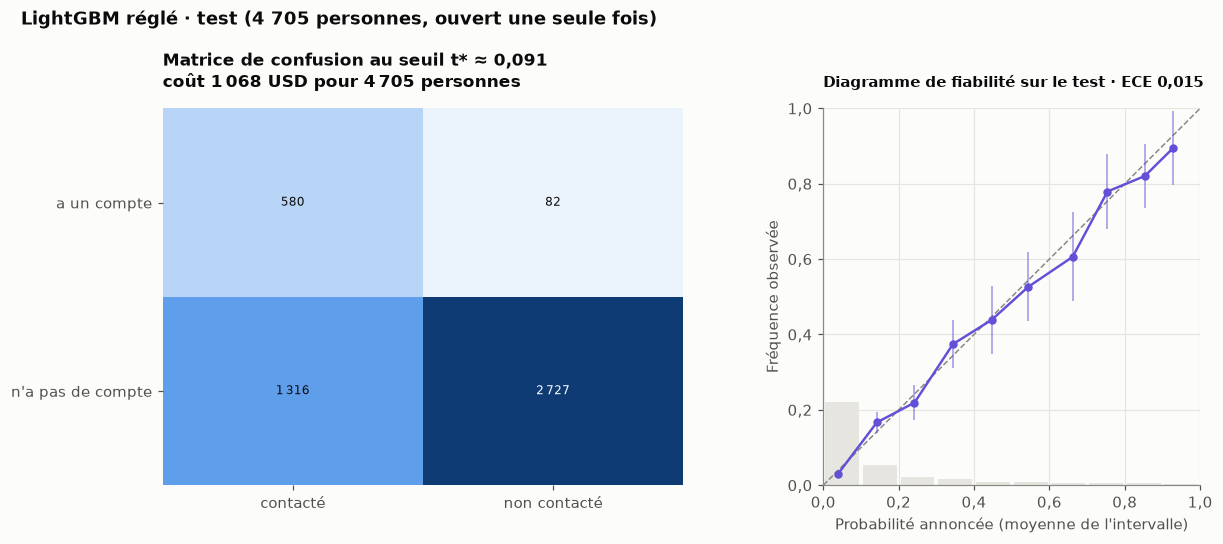

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.1]})
cm = pd.DataFrame([[tp, fn], [fp, tn]], index=["a un compte", "n'a pas de compte"],
                  columns=["contacté", "non contacté"])
viz.heatmap(axes[0], cm, f"Matrice de confusion au seuil t* ≈ 0,091\ncoût {viz.fmt_int(decision.iloc[0]['coût (USD)'])} USD "
            f"pour {viz.fmt_int(n_test)} personnes", fmt="{:,.0f}", vmin=0, vmax=n_test * 0.6)
axes[0].set_xticks(range(2), cm.columns, rotation=0, ha="center")
ece = test_table.loc["ECE", "test"]
viz.reliability(axes[1], y_test, p_test, hist=True, color=viz.COMPOSITION[1])
axes[1].set_title(f"Diagramme de fiabilité sur le test · ECE {viz.fr(f'{ece:.3f}')}", fontsize=10)
fig.suptitle(f"{models.FINAL_MODEL} · test (4 705 personnes, ouvert une seule fois)", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "10_test_confusion_fiabilite")
plt.show()

**Réponse Q10.1.**

| Métrique (test) | Valeur | IC 95 % bootstrap | Validation croisée |
|---|---|---|---|
| **PR-AUC** | **0,597** | [0,559 ; 0,635] | 0,581 ± 0,024 |
| ROC-AUC | 0,876 | [0,861 ; 0,889] | 0,861 ± 0,010 |
| Brier | 0,083 | [0,077 ; 0,088] | 0,085 ± 0,003 |
| log-loss | 0,274 | [0,259 ; 0,290] | 0,283 ± 0,009 |
| ECE | 0,015 | [0,011 ; 0,025] | 0,005 (hors pli) |
| Précision / recall au seuil $t^*$ | 0,306 / 0,876 | [0,286 ; 0,326] / [0,851 ; 0,902] | 0,301 / 0,852 |
| **Coût par personne** | **0,227 USD** | [0,207 ; 0,247] | 0,244 ± 0,012 |

**Matrice de confusion au seuil $t^*$** : 1 896 personnes contactées sur 4 705 ; 580 vrais positifs, 1 316 contacts inutiles, **82 personnes oubliées** sur 662, 2 727 vrais négatifs. **Coût total : 1 068 USD** (1 316 × 0,5 + 82 × 5), contre 2 021,5 USD pour contacter tout le monde et 3 310 USD pour ne contacter personne.

**Calibration sur le test.** L'ECE (0,015) est un peu au-dessus de son plancher de bruit sur 4 705 personnes (moyenne 0,010, 95e centile 0,014, ci-dessous) : le modèle annonce 680 personnes qui ont un compte pour 662 réelles (+2,7 %, 0,9 écart-type du bruit attendu). Écart léger, sans conséquence pour le seuil (le coût est plat autour de $t^*$, étape 9).

In [9]:
floor = ece_noise_floor(p_test)
print(f"ECE test {expected_calibration_error(y_test, p_test):.4f} · plancher : moyenne {floor['moyenne']:.4f}, "
      f"95e centile {floor['95e centile']:.4f}")
expected_counts(y_test, p_test, X_test["country"]).round(3)

ECE test 0.0149 · plancher : moyenne 0.0098, 95e centile 0.0137


,réel,attendu,écart,erreur relative,écart-type attendu,écart / écart-type
Kenya,314.0,303.399,-10.601,-0.034,12.475,-0.850
Rwanda,195.0,213.492,18.492,0.095,11.922,1.551
Tanzania,117.0,121.206,4.206,0.036,8.504,0.495
Uganda,36.0,41.621,5.621,0.156,5.353,1.050
Total,662.0,679.718,17.718,0.027,19.968,0.887


### Q10.2 · L'estimation de validation croisée tombe-t-elle dans l'intervalle du test ?

In [10]:
COMPARE = {"PR-AUC": ("pr_auc", "PR-AUC"), "ROC-AUC": ("roc_auc", "ROC-AUC"), "Brier": ("brier", "Brier"),
           "Coût par personne (USD)": ("cost_t", "coût / personne (USD)")}
rows = {}
for label, (cv_key, test_key) in COMPARE.items():
    cv_mean = cv_row[(cv_key, "val", "mean")]
    lo, hi = test_table.loc[test_key, ["IC 95 % bas", "IC 95 % haut"]]
    rows[label] = {"CV (moyenne des plis)": cv_mean, "CV écart-type": cv_row[(cv_key, "val", "std")],
                   "test": test_table.loc[test_key, "test"], "IC 95 % bas": lo, "IC 95 % haut": hi,
                   "CV dans l'IC ?": "oui" if lo <= cv_mean <= hi else "non"}
q102 = pd.DataFrame(rows).T
q102

,CV (moyenne des plis),CV écart-type,test,IC 95 % bas,IC 95 % haut,CV dans l'IC ?
PR-AUC,0.5815,0.0237,0.5969,0.559,0.6349,oui
ROC-AUC,0.8612,0.0103,0.8755,0.8609,0.8885,oui
Brier,0.0845,0.0025,0.0826,0.0771,0.088,oui
Coût par personne (USD),0.2437,0.0123,0.227,0.2073,0.2468,oui


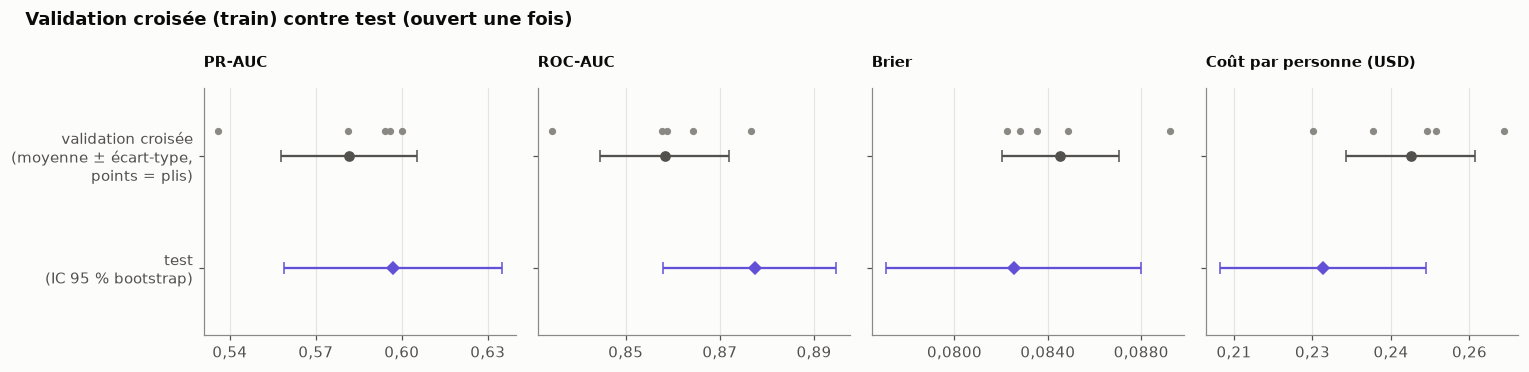

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (label, (cv_key, test_key)) in zip(axes, COMPARE.items()):
    folds = cv_folds[cv_key].to_numpy()
    mean, sd = folds.mean(), folds.std()
    ax.errorbar(mean, 1, xerr=sd, fmt="o", color=viz.INK_2, capsize=4, ms=6)
    ax.scatter(folds, np.full(len(folds), 1.22), color=viz.INK_3, s=14, zorder=3)
    t_val = test_table.loc[test_key, "test"]
    lo, hi = test_table.loc[test_key, ["IC 95 % bas", "IC 95 % haut"]]
    ax.errorbar(t_val, 0, xerr=[[t_val - lo], [hi - t_val]], fmt="D", color=viz.COMPOSITION[1], capsize=4, ms=6)
    ax.set_yticks([0, 1], ["test\n(IC 95 % bootstrap)", "validation croisée\n(moyenne ± écart-type,\npoints = plis)"])
    ax.set_ylim(-0.6, 1.6)
    ax.set_title(label, fontsize=10)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    viz.fr_axis(ax, "x", {"brier": "{:.4f}", "cost_t": "{:.2f}"}.get(cv_key, "{:.2f}"))
    ax.grid(axis="y", visible=False)
    if ax is not axes[0]:
        ax.set_yticklabels([])
fig.suptitle("Validation croisée (train) contre test (ouvert une fois)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "10_cv_contre_test")
plt.show()

**Réponse Q10.2. Oui, pour les quatre métriques** : PR-AUC 0,581, ROC-AUC 0,861, Brier 0,085 et coût 0,244 USD par personne tombent dans les intervalles du test. Le test est même un peu **meilleur** que la validation croisée (PR-AUC 0,597, coût 0,227 USD par personne).

**La ROC-AUC est à la limite** : 0,8612 pour une borne basse de 0,8609. Avec une autre graine de bootstrap (0 au lieu de 42), la borne devient 0,8621 et la validation croisée tombe juste dehors : la frontière d'un intervalle à 95 % n'est pas une ligne nette. Ce n'est pas alarmant :

- l'intervalle bootstrap ne mesure que le hasard de **l'échantillon de test**, pour un modèle fixé ; il ignore la variabilité du découpage et de l'entraînement, que l'écart-type entre plis (0,010) capture. L'écart (0,014) vaut 1,4 écart-type entre plis ;
- le modèle final est entraîné sur **25 % de lignes en plus** que dans chaque pli : il peut être un peu meilleur que l'estimation de validation croisée, légèrement pessimiste (slide 22) ;
- l'écart va dans le sens **favorable**. Une fuite d'information se verrait plutôt dans une validation croisée trop belle, démentie par le test ; c'est l'inverse ici.

**Conclusion** : la validation croisée était une estimation fiable de la performance sur des personnes nouvelles ; le protocole (test sous scellé, mêmes plis, décisions prises sur le train) a tenu. On rapporte les chiffres du **test** comme estimation finale, avec leurs intervalles : PR-AUC 0,597 [0,559 ; 0,635], coût 0,227 USD par personne [0,207 ; 0,247]. La largeur de ces intervalles (± 0,04 de PR-AUC) rappelle que les écarts de 0,003 entre candidats aux étapes 7–9 étaient indiscernables sur un test de cette taille.

### Retour sur Q2.6 · la modalité rare *Other/Dont know/RTA*

Le modèle final lui a donné sa propre modalité (21 occurrences dans le train). Change-t-elle les prédictions des 14 personnes du test qui la portent ? On compare avec les mêmes personnes, modalité remplacée par une valeur jamais vue (donc `infrequent`).

In [12]:
rare = X_test["education_level"] == "Other/Dont know/RTA"
p_rare = final.predict_proba(X_test[rare])[:, 1]
X_swap = X_test[rare].assign(education_level="jamais vue")
p_swap = final.predict_proba(X_swap)[:, 1]
pd.Series({"personnes du test": int(rare.sum()),
           "probabilité moyenne prédite": p_rare.mean(),
           "part réelle qui a un compte": y_test[rare].mean(),
           "écart maximal si la modalité devient « infrequent »": np.abs(p_rare - p_swap).max()}).to_frame("valeur")

,valeur
personnes du test,14.0000
probabilité moyenne prédite,0.3712
part réelle qui a un compte,0.2143
écart maximal si la modalité devient « infrequent »,0.0000


Aucune différence : LightGBM ne crée pas de branche pour une modalité aussi rare (`min_child_samples = 23` et `min_data_per_group = 100` par défaut pour les catégories), elle suit le même chemin que `infrequent`. Le changement de statut entre la validation croisée et le modèle final est donc **sans effet** ici. Sur 14 personnes, l'écart entre probabilité moyenne (0,37) et fréquence observée (0,21, soit 3 personnes) n'est pas interprétable.

### Q10.3 · Pourquoi ne plus toucher au modèle ?

**Parce que le test cesserait d'être un test.** Il donne une estimation honnête uniquement s'il n'a influencé aucune décision. Si l'on modifie le modèle après avoir vu ces chiffres (autre seuil, autres variables, autre modèle), on choisit en fonction du test : il devient un jeu de validation, et ses chiffres deviennent **optimistes**, exactement comme `best_score_` à l'étape 7 (comparaisons multiples, slide 24). Avec ± 0,04 de PR-AUC d'incertitude, retoucher jusqu'à « faire mieux » sur 4 705 personnes revient surtout à ajuster le bruit de ce test.

**Si on le fait malgré tout**, le README doit l'écrire clairement :

1. que le test a été consulté **plusieurs fois**, combien de fois, et ce qui a été modifié après chaque consultation ;
2. les chiffres **avant et après** la modification ;
3. que les chiffres finaux sont **optimistes** et ne sont plus une estimation non biaisée ;
4. idéalement, une nouvelle mesure sur des données jamais vues (nouvelle vague d'enquête FinScope, autre année) pour retrouver une estimation honnête.

Ici, rien n'a été modifié : le test a été ouvert une fois, et le README le dit.

### Synthèse de l'étape 10

| | Test (IC 95 %) | Validation croisée |
|---|---|---|
| PR-AUC | **0,597** [0,559 ; 0,635] | 0,581 ± 0,024 |
| ROC-AUC | 0,876 [0,861 ; 0,889] | 0,861 ± 0,010 |
| Brier | 0,083 [0,077 ; 0,088] | 0,085 ± 0,003 |
| Coût par personne au seuil $t^*$ | **0,227 USD** [0,207 ; 0,247] | 0,244 ± 0,012 |
| Recall / précision au seuil $t^*$ | 0,876 / 0,306 | 0,852 / 0,301 |

Le modèle final contacte 40 % des personnes, retrouve 88 % de celles qui ont un compte bancaire et coûte **47 % de moins** que de contacter tout le monde (1 068 contre 2 021,5 USD sur le test). **Étape 11** : comprendre ce que le modèle a appris (importance par permutation, SHAP).